# Low-Dimensional Subspace Optimization for Unlearnable Data
**CS F320 Foundations of Data Science · BITS Pilani Dubai**
Group project

We add an invisible, class-wise "stamp" to CIFAR-10 training images. A model trained on the stamped
images fails on clean images. Here we ask: what happens if the stamp may only use k directions chosen
from PCA (top, middle, bottom) or from random directions?


---



# Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, csv, numpy as np, torch, pandas as pd, matplotlib.pyplot as plt

PROJECT = '/content/drive/MyDrive/FDS_ULD_PCA'
RESULTS = f'{PROJECT}/results.csv'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

d = np.load(f'{PROJECT}/cifar10_uint8.npz')
x_train = torch.tensor(d['xtr']).permute(0, 3, 1, 2).float().div(255).to(device)   # (50000, 3, 32, 32) in [0, 1]
y_train = torch.tensor(np.asarray(d['ytr'])).long().flatten().to(device)
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
print('Loaded', tuple(x_train.shape), 'on', device)

needed = ['results.csv',
          'delta_pca_100_bottom_s0.pt', 'delta_pca_100_top_s0.pt',
          'delta_random_100_-_s0.pt', 'delta_full-space_3072_-_s0.pt']
for f in needed:
    print('OK      ' if os.path.exists(f'{PROJECT}/{f}') else 'MISSING ', f)

Mounted at /content/drive
Loaded (50000, 3, 32, 32) on cuda
OK       results.csv
OK       delta_pca_100_bottom_s0.pt
OK       delta_pca_100_top_s0.pt
OK       delta_random_100_-_s0.pt
OK       delta_full-space_3072_-_s0.pt


# Clean vs Protected images

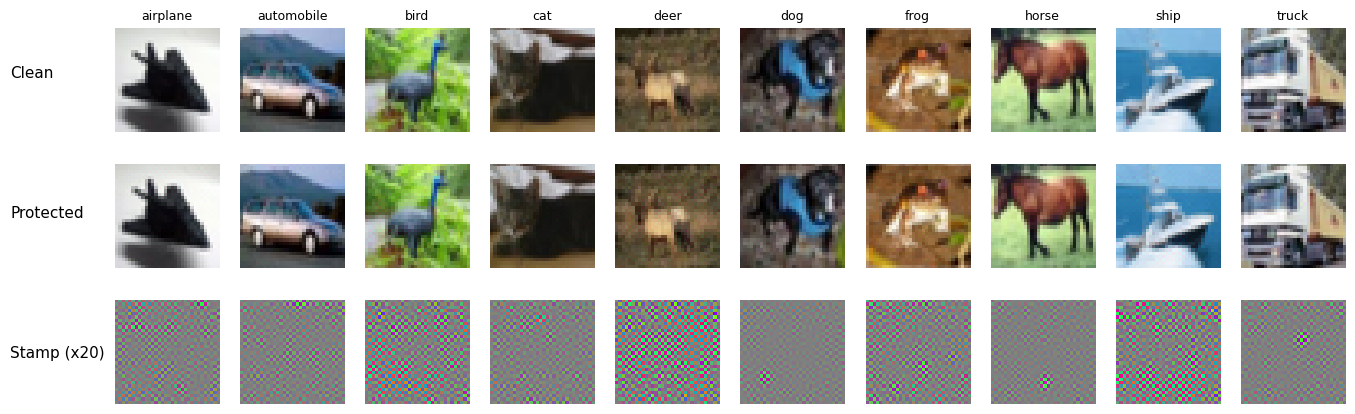

Largest pixel change: 8.0 out of 255


In [2]:
delta = torch.load(f'{PROJECT}/delta_pca_100_bottom_s0.pt', map_location=device)

idx = [int((y_train == c).nonzero()[0]) for c in range(10)]
clean = x_train[idx]
protected = (clean + delta).clamp(0, 1)
stamp_vis = (delta * 20 + 0.5).clamp(0, 1)

def show(t): return t.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for r, imgs in enumerate([clean, protected, stamp_vis]):
    for c in range(10):
        axes[r, c].imshow(show(imgs[c])); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(classes[c], fontsize=9)
fig.subplots_adjust(left=0.08)
for y, name in [(0.78, 'Clean'), (0.50, 'Protected'), (0.22, 'Stamp (x20)')]:
    fig.text(0.01, y, name, fontsize=11, va='center')
plt.show()
print(f'Largest pixel change: {float(delta.abs().max()) * 255:.1f} out of 255')

# Does the protection work?

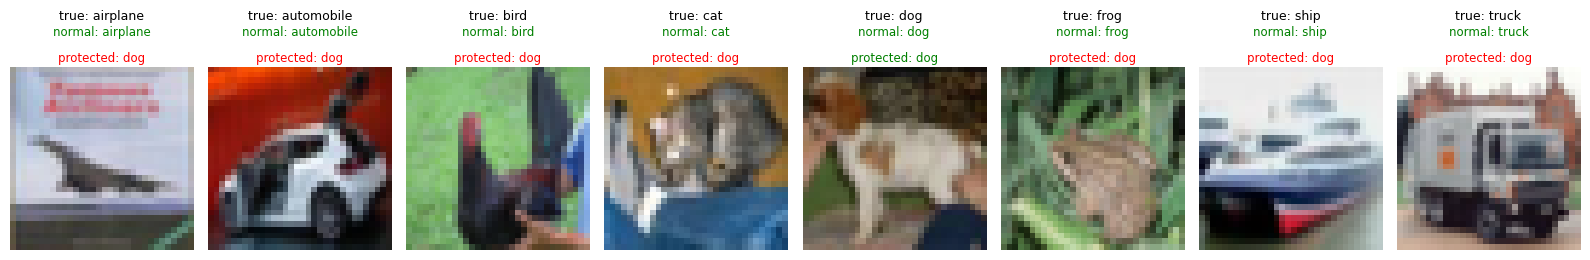

Normal model,    clean test images:        92.3%
Protected model, clean test images:        10.0%
Protected model, stamped training images: 100.0%   <- it learned the stamp


In [3]:
import torch.nn as nn, torchvision

MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.mean) / self.std

def make_resnet18():
    r = torchvision.models.resnet18(num_classes=10)
    r.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
    r.maxpool = nn.Identity()
    return nn.Sequential(Normalize(MEAN, STD), r).to(device)

def load_model(name):
    m = make_resnet18()
    m.load_state_dict(torch.load(f'{PROJECT}/{name}', map_location=device))
    return m.eval()

clean_model = load_model('demo_model_clean.pt')
prot_model  = load_model('demo_model_protected.pt')

cifar = np.load(f'{PROJECT}/cifar10_uint8.npz')
x_test = torch.tensor(cifar['xte']).permute(0, 3, 1, 2).float().div(255).to(device)
y_test = torch.tensor(np.asarray(cifar['yte'])).long().flatten().to(device)
delta = torch.load(f'{PROJECT}/delta_pca_100_bottom_s0.pt', map_location=device)
x_stamped = (x_train[:10000] + delta[y_train[:10000]]).clamp(0, 1)

@torch.no_grad()
def predict(m, x): return torch.cat([m(x[i:i+1000]).argmax(1) for i in range(0, len(x), 1000)])
def acc(m, x, y): return 100 * (predict(m, x) == y).float().mean().item()

# 8 clean test images, a fixed spread of classes
sel = [int((y_test == c).nonzero()[0]) for c in (0, 1, 2, 3, 5, 6, 8, 9)]
pc, pp = predict(clean_model, x_test[sel]), predict(prot_model, x_test[sel])

fig, axes = plt.subplots(1, 8, figsize=(16, 3.6))
for a, i, c, p in zip(axes, sel, pc, pp):
    true = int(y_test[i])
    a.imshow(x_test[i].permute(1, 2, 0).cpu().numpy()); a.axis('off')
    a.set_title(f'true: {classes[true]}', fontsize=9, pad=34)
    a.text(0.5, 1.17, f'normal: {classes[int(c)]}', transform=a.transAxes, ha='center', fontsize=8.5,
           color='green' if int(c) == true else 'red')
    a.text(0.5, 1.03, f'protected: {classes[int(p)]}', transform=a.transAxes, ha='center', fontsize=8.5,
           color='green' if int(p) == true else 'red')
plt.tight_layout(); plt.show()

print(f'Normal model,    clean test images:       {acc(clean_model, x_test, y_test):5.1f}%')
print(f'Protected model, clean test images:       {acc(prot_model,  x_test, y_test):5.1f}%')
print(f'Protected model, stamped training images: {acc(prot_model, x_stamped, y_train[:10000]):5.1f}%   <- it learned the stamp')

# Stamps Compared

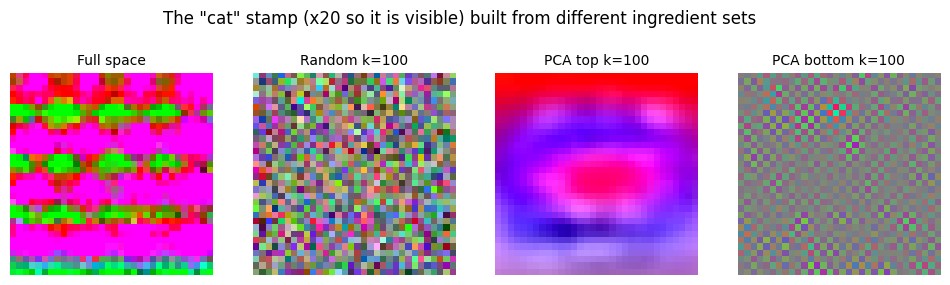

In [4]:
files = [('Full space',       'delta_full-space_3072_-_s0.pt'),
         ('Random k=100',     'delta_random_100_-_s0.pt'),
         ('PCA top k=100',    'delta_pca_100_top_s0.pt'),
         ('PCA bottom k=100', 'delta_pca_100_bottom_s0.pt')]
cls = 3                                           # 3 = cat

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (name, f) in zip(axes, files):
    path = f'{PROJECT}/{f}'
    if not os.path.exists(path):
        ax.set_title(name + '\n(file missing)', fontsize=9); ax.axis('off'); continue
    dl = torch.load(path, map_location='cpu')[cls]
    ax.imshow((dl * 20 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=10); ax.axis('off')
fig.suptitle('The "cat" stamp (x20 so it is visible) built from different ingredient sets')
plt.show()

# Directions Gallery

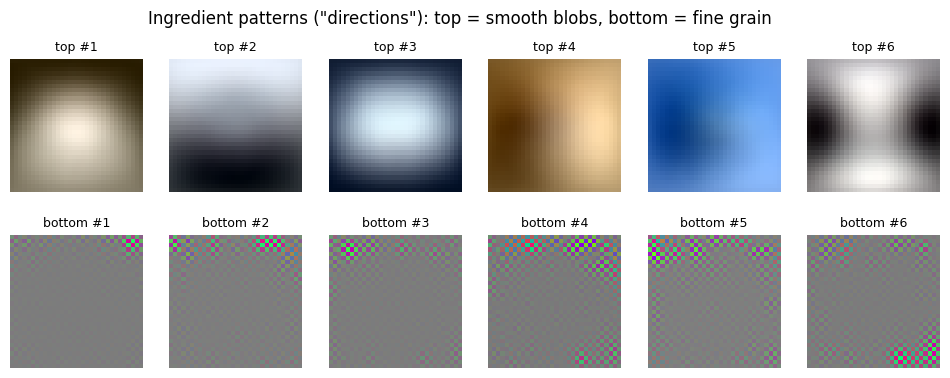

Variance explained by the top 100 directions: 90.1%


In [5]:
X = x_train.reshape(len(x_train), -1).float()                  # each image as a row of 3072 numbers
Xc = X - X.mean(0, keepdim=True)                               # subtract the average image
cov = (Xc.T @ Xc) / (len(Xc) - 1)                              # how pixels vary together
evals, evecs = torch.linalg.eigh(cov.double())                 # PCA: directions (smallest first)
evals, evecs = evals.flip(0).float(), evecs.flip(1).float()    # now biggest first
del X, Xc, cov

def as_img(v):
    v = v.reshape(3, 32, 32)
    return ((v - v.min()) / (v.max() - v.min())).permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for j in range(6):
    axes[0, j].imshow(as_img(evecs[:, j]));      axes[0, j].set_title(f'top #{j+1}', fontsize=9)
    axes[1, j].imshow(as_img(evecs[:, -1 - j])); axes[1, j].set_title(f'bottom #{j+1}', fontsize=9)
    axes[0, j].axis('off'); axes[1, j].axis('off')
fig.suptitle('Ingredient patterns ("directions"): top = smooth blobs, bottom = fine grain')
plt.show()

print('Variance explained by the top 100 directions: '
      f'{float(evals[:100].sum() / evals.sum()) * 100:.1f}%')

# How much of each stamp is Fine Grain?

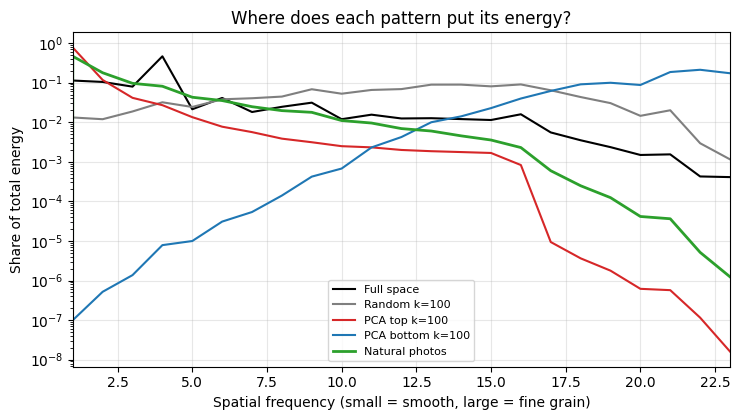

Full space          13.8% of the energy is fine grain (frequency > 8)
Random k=100        77.8% of the energy is fine grain (frequency > 8)
PCA top k=100        1.6% of the energy is fine grain (frequency > 8)
PCA bottom k=100   100.0% of the energy is fine grain (frequency > 8)
Natural photos       6.3% of the energy is fine grain (frequency > 8)


In [6]:
def energy_by_frequency(imgs):
    """imgs: (N,3,32,32) -> share of total energy at each spatial frequency (0 = smooth ... ~23 = finest grain)."""
    x = imgs.float().cpu()
    p = (torch.fft.fftshift(torch.fft.fft2(x), dim=(-2, -1)).abs() ** 2).mean(dim=(0, 1)).numpy()
    yy, xx = np.indices(p.shape)
    r = np.round(np.hypot(yy - 16, xx - 16)).astype(int)     # distance from the centre = frequency
    e = np.bincount(r.ravel(), weights=p.ravel())
    e[0] = 0                                                 # ignore overall tint/brightness
    return e / e.sum()

files = [('Full space',       'delta_full-space_3072_-_s0.pt'),
         ('Random k=100',     'delta_random_100_-_s0.pt'),
         ('PCA top k=100',    'delta_pca_100_top_s0.pt'),
         ('PCA bottom k=100', 'delta_pca_100_bottom_s0.pt')]
colours = ['black', 'tab:gray', 'tab:red', 'tab:blue']

spectra = {name: energy_by_frequency(torch.load(f'{PROJECT}/{f}', map_location='cpu')) for name, f in files}
spectra['Natural photos'] = energy_by_frequency(x_train[:2000])    # 2000 clean training images

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for (name, e), c in zip(spectra.items(), colours + ['tab:green']):
    ax.plot(range(len(e)), e, label=name, color=c, lw=2 if name == 'Natural photos' else 1.5)
ax.set_yscale('log'); ax.set_xlabel('Spatial frequency (small = smooth, large = fine grain)')
ax.set_ylabel('Share of total energy'); ax.set_title('Where does each pattern put its energy?')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); ax.set_xlim(1, 23); plt.show()

for name, e in spectra.items():
    print(f'{name:18s} {e[9:].sum() * 100:5.1f}% of the energy is fine grain (frequency > 8)')

# Headline Bar Chart

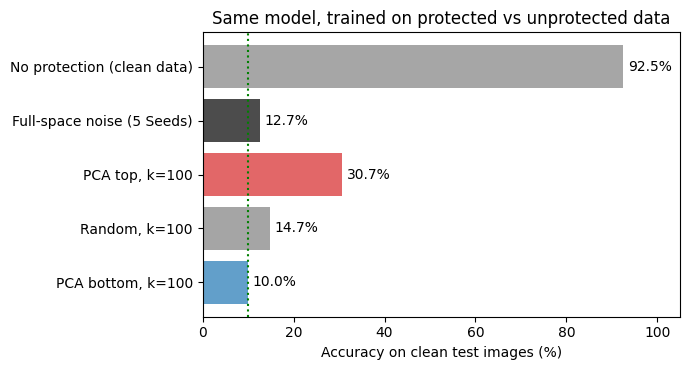

In [7]:
r = pd.read_csv(RESULTS)
r['k'] = pd.to_numeric(r['k'], errors='coerce')            # k is '-' on the baseline rows, so convert safely

def m(mask): return r[mask].clean_test_acc.mean()
vals = {
    'No protection (clean data)': m(r.method == 'clean'),
    'Full-space noise (5 Seeds)':  m(r.method == 'full-space'),
    'PCA top, k=100':    m((r.method == 'pca') & (r.k == 100) & (r.region == 'top')),
    'Random, k=100':     m((r.method == 'random') & (r.k == 100)),
    'PCA bottom, k=100': m((r.method == 'pca') & (r.k == 100) & (r.region == 'bottom')),
}

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(list(vals), list(vals.values()),
        color=['gray', 'black', 'tab:red', 'tab:gray', 'tab:blue'], alpha=0.7)
for i, v in enumerate(vals.values()):
    ax.text(v + 1, i, f'{v:.1f}%', va='center')
ax.axvline(10, ls=':', color='green'); ax.invert_yaxis()
ax.set_xlabel('Accuracy on clean test images (%)'); ax.set_xlim(0, 105)
ax.set_title('Same model, trained on protected vs unprotected data')
fig.tight_layout(); fig.savefig(f'{PROJECT}/plot_headline.png', dpi=200); plt.show()

# Table and accuracy/regions plots

method region    k  runs  mean  std  median  lowest  highest  runs_above_50
   pca bottom    2     3  68.2 42.1    92.5    19.7     92.6              2
   pca bottom    3     3  64.9 47.5    92.2    10.0     92.4              2
   pca bottom    5     5  42.9 45.0    10.2    10.0     92.7              2
   pca bottom   10     5  43.0 45.3    10.0    10.0     92.6              2
   pca bottom   25     5  26.5 36.9    10.0    10.0     92.5              1
   pca bottom  100     5  10.0  0.0    10.0    10.0     10.0              0
   pca bottom  500     3  10.0  0.0    10.0    10.0     10.0              0
   pca middle  100     5  24.9 10.1    30.1    10.7     34.4              0
   pca    top   25     3  63.6  0.2    63.6    63.4     63.8              3
   pca    top  100     5  30.7  4.5    29.5    26.0     37.9              0
   pca    top  500     3  26.4  4.7    23.9    23.6     31.9              0
   pca    top 3072     5  28.7 35.1    14.4    10.4     91.4              1
random      

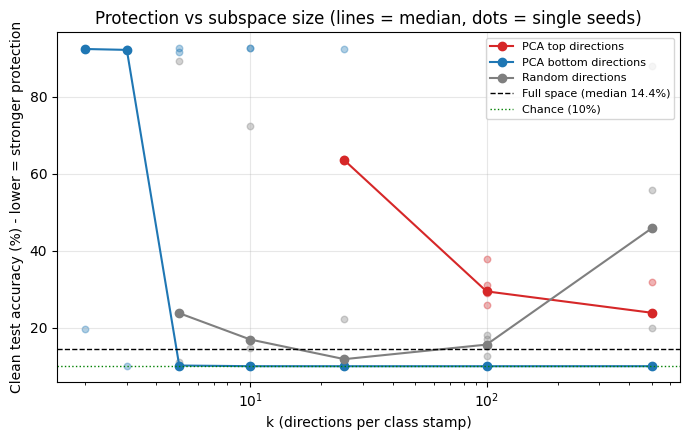

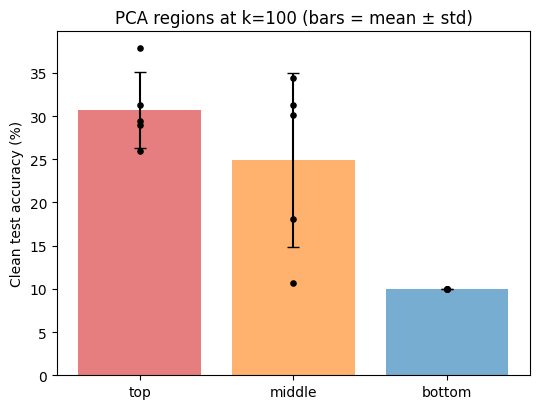

In [8]:
df = pd.read_csv(RESULTS)
df = df[df.method.isin(['pca', 'random'])].copy()      # leaves out 'pca-long' and the reference rows
df['k'] = df['k'].astype(int)

summary = (df.groupby(['method', 'region', 'k']).clean_test_acc
             .agg(runs='count', mean='mean', std='std', median='median', lowest='min', highest='max')
             .round(1).reset_index())
fails = (df.assign(failed=df.clean_test_acc > 50)
           .groupby(['method', 'region', 'k']).failed.sum().reset_index(name='runs_above_50'))
summary = summary.merge(fails, on=['method', 'region', 'k'])
print(summary.to_string(index=False))
summary.to_csv(f'{PROJECT}/summary_table.csv', index=False)

# Plot 1: accuracy vs k
fig, ax = plt.subplots(figsize=(7, 4.5))
series = [('pca', 'top', 'PCA top directions', 'tab:red'),
          ('pca', 'bottom', 'PCA bottom directions', 'tab:blue'),
          ('random', '-', 'Random directions', 'tab:gray')]
for method, region, label, colour in series:
    s = df[(df.method == method) & (df.region == region) & (df.k < 3072)]
    if s.empty: continue
    med = s.groupby('k').clean_test_acc.median()
    ax.scatter(s.k, s.clean_test_acc, color=colour, alpha=0.35, s=22)
    ax.plot(med.index, med.values, marker='o', color=colour, label=label)
full = df[(df.method == 'pca') & (df.k == 3072)].clean_test_acc.median()
ax.axhline(full, ls='--', color='k', lw=1, label=f'Full space (median {full:.1f}%)')
ax.axhline(10, ls=':', color='green', lw=1, label='Chance (10%)')
ax.set_xscale('log'); ax.set_xlabel('k (directions per class stamp)')
ax.set_ylabel('Clean test accuracy (%) - lower = stronger protection')
ax.set_title('Protection vs subspace size (lines = median, dots = single seeds)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(f'{PROJECT}/plot_acc_vs_k.png', dpi=200); plt.show()

# Plot 2: top / middle / bottom at k=100
fig, ax = plt.subplots(figsize=(5.5, 4.2))
cols = ['tab:red', 'tab:orange', 'tab:blue']
for i, reg in enumerate(['top', 'middle', 'bottom']):
    s = df[(df.method == 'pca') & (df.k == 100) & (df.region == reg)].clean_test_acc
    ax.bar(i, s.mean(), color=cols[i], alpha=0.6, yerr=s.std() if len(s) > 1 else 0, capsize=4)
    ax.scatter([i] * len(s), s, color='k', s=14, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(['top', 'middle', 'bottom'])
ax.set_ylabel('Clean test accuracy (%)'); ax.set_title('PCA regions at k=100 (bars = mean ± std)')
fig.tight_layout(); fig.savefig(f'{PROJECT}/plot_regions_k100.png', dpi=200); plt.show()

# Success-rate plot

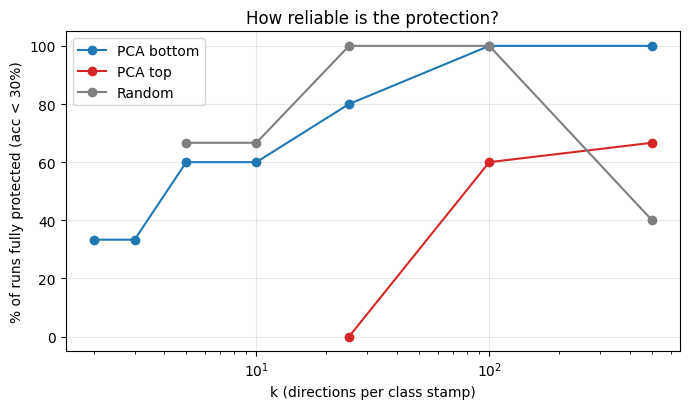

In [9]:
d = pd.read_csv(RESULTS)
d = d[d.method.isin(['pca', 'random'])].copy()
d['k'] = d['k'].astype(int)
d['protected'] = d.clean_test_acc < 30

fig, ax = plt.subplots(figsize=(7, 4.2))
for method, region, label, colour in [('pca', 'bottom', 'PCA bottom', 'tab:blue'),
                                      ('pca', 'top', 'PCA top', 'tab:red'),
                                      ('random', '-', 'Random', 'tab:gray')]:
    s = d[(d.method == method) & (d.region == region) & (d.k < 3072)]
    rate = s.groupby('k').protected.mean() * 100
    ax.plot(rate.index, rate.values, marker='o', color=colour, label=label)
ax.set_xscale('log'); ax.set_ylim(-5, 105)
ax.set_xlabel('k (directions per class stamp)'); ax.set_ylabel('% of runs fully protected (acc < 30%)')
ax.set_title('How reliable is the protection?'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{PROJECT}/plot_success_rate.png', dpi=200); plt.show()

# Late-collapse chart

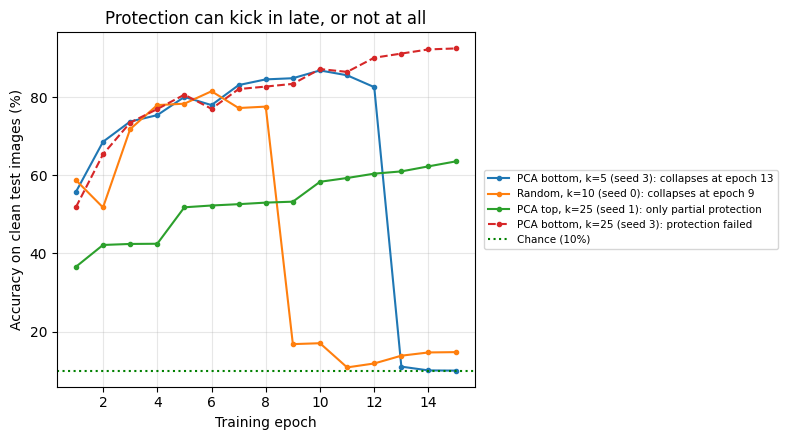

In [10]:
curves = {
 'PCA bottom, k=5 (seed 3): collapses at epoch 13':
     [55.73,68.58,73.75,75.40,80.06,77.97,83.09,84.55,84.85,86.84,85.60,82.57,11.03,10.06,10.01],
 'Random, k=10 (seed 0): collapses at epoch 9':
     [58.77,51.77,71.81,77.97,78.33,81.51,77.22,77.58,16.79,17.02,10.83,11.84,13.83,14.66,14.74],
 'PCA top, k=25 (seed 1): only partial protection':
     [36.58,42.17,42.43,42.48,51.81,52.27,52.61,53.01,53.25,58.34,59.31,60.42,61.00,62.29,63.55],
 'PCA bottom, k=25 (seed 3): protection failed':
     [51.83,65.37,73.48,76.95,80.64,77.02,82.07,82.71,83.40,87.19,86.47,90.09,91.16,92.22,92.47],
}
styles = ['-', '-', '-', '--']
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, c), ls in zip(curves.items(), styles):
    ax.plot(range(1, 16), c, ls, marker='o', ms=3, label=name)
ax.axhline(10, ls=':', color='green', label='Chance (10%)')
ax.set_xlabel('Training epoch'); ax.set_ylabel('Accuracy on clean test images (%)')
ax.set_title('Protection can kick in late, or not at all')
ax.legend(fontsize=7.5, loc='center left', bbox_to_anchor=(1.01, 0.5))
ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

# Conclusions
1. An invisible stamp (at most 8/255 change per pixel) takes a ResNet-18 trained on CIFAR-10 from
   92.5% to about 10% accuracy on clean test images. The live check shows it directly: on the same
   clean images a normal model scores 92.3% and the protected model 10.0%, while the protected model
   scores 100% on stamped training images, so it learned the stamp instead of the content.
2. The type of direction matters more than how many we use. Fine-grain (bottom) PCA directions gave
   exactly 10.0% in all 8 runs at k >= 100. Random directions worked in 8 of 8 runs at k = 25-100,
   but only 2 of 5 at k = 500. Smooth (top) PCA directions only partly protect (26-38% at k = 100,
   63% at k = 25).
3. Very small k is a gamble for every kind of direction: bottom directions protected 33% of runs at
   k = 2-3, 60% at k = 5-10 and 80% at k = 25.
4. Frequency analysis: across PCA and random stamps, protection tracks the share of fine-grain energy
   (bottom 100% -> 10.0%, random 78% -> 14.7%, top 1.6% -> 30.7%). The free-form full-space stamp is
   mostly smooth but protects through higher energy, so fine grain is one route to protection,
   not the only one.
5. Efficiency: a stamp at k = 100 is described by about 1,000 numbers instead of 30,720, but
   generation was not faster (17-24 s vs 23-26 s), because training the surrogate model dominates.

# Limitations
- Protection can kick in late (epochs 9-13) or fail entirely, so early stopping or an unlucky seed
  gives an attacker a useful model.
- One dataset (CIFAR-10), one model (ResNet-18), class-wise noise only, one budget (8/255).
- 3-5 runs per setting, so close numbers (for example top vs middle PCA) cannot be ranked.
- The frequency result is consistent with our explanation but is not a causal test.
- We did not test defences such as blurring or compressing the images before training.

# Future work
Other noise budgets, sample-wise noise, CIFAR-100, other architectures, blur and JPEG defences (which
would also test the frequency explanation directly), and detecting protected images before training.